<a href="https://colab.research.google.com/github/wawaelenti/Machine-Learning/blob/main/DEMO_PRAK_6_ANN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Nama:** Wawa Elent Irawanti

**NIM:** 244107020192

**Kelas:** TI-3H

## **Praktikum 1 ANNOY**

**Instalasi annoy**

In [ ]:
!pip install annoy

### **Code**

Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 0.3819 ms

Annoy NN index: [219, 898, 770]
Annoy NN jarak: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.568167959732514)]
Waktu Annoy: 0.1175 ms


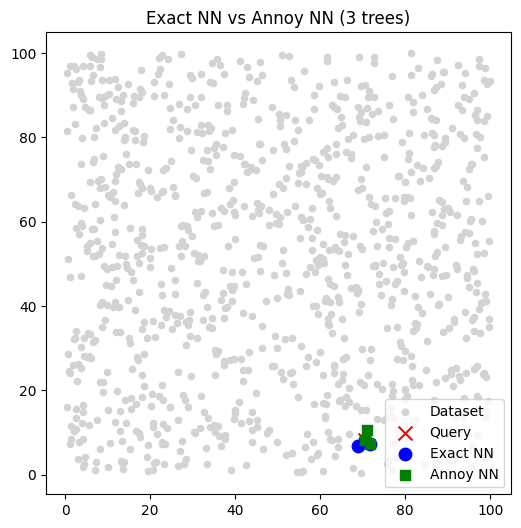

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

# 1. Dataset 2D
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # titik random dalam ruang 100x100

# Query point (ambil salah satu titik random)
query = X[np.random.randint(0, n_points)]

# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

# 3. Annoy NN (3 tree)
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # cari 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")

# 4. Visualisasi hasil
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN ditandai biru
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN ditandai hijau
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

**Tabel hasil**

| Distance Metrics | Tree | Jumlah Data | Hasil Index Terdekat ENN vs ANN | Waktu Komputasi ENN vs ANN |
|---|---:|---:|---|---|
| Euclidean | 3 | 1.000 | [219, 898, 593] vs [219, 898, 770] | 0.3819 ms vs 0.1175 ms |
| Euclidean | 8 | 1.000 | ... | ... |
| Euclidean | 3 | 100.000 | ... | ... |
| Angular | 3 | 1.000 | ... | ... |
| Angular | 8 | 1.000 | ... | ... |
| Angular | 3 | 100.000 | ... | ... |

### **Code**

In [ ]:
import numpy as np
import time
from sklearn.metrics.pairwise import euclidean_distances
from annoy import AnnoyIndex

# ---- 1. Buat dataset mirip Spotify ----
n_tracks = 50_000_000   # 50 juta track
n_features = 20        # contoh: danceability, energy, tempo, dll.

# dataset besar (random untuk simulasi)
X = np.random.rand(n_tracks, n_features).astype(np.float32)

# query track (misalnya lagu baru)
query = np.random.rand(1, n_features).astype(np.float32)

# ---- 2. Exact NN (brute force) ----
start = time.time()
distances = euclidean_distances(query, X)[0]   # hitung semua jarak
exact_idx = np.argsort(distances)[:5]          # ambil 5 terdekat
exact_time = time.time() - start

print("Exact NN result:", exact_idx)
print("Exact NN time:", round(exact_time, 3), "seconds")

# ---- 3. Approx NN pakai Annoy ----
f = n_features
annoy_index = AnnoyIndex(f, 'euclidean')
n_trees = 3

# build index
for i in range(n_tracks):
    annoy_index.add_item(i, X[i])
annoy_index.build(n_trees)

start = time.time()
annoy_idx = annoy_index.get_nns_by_vector(query[0], 5)  # ambil 5 lagu yang mirip
annoy_time = time.time() - start

print("Annoy result:", annoy_idx)
print("Annoy time:", round(annoy_time, 3), "seconds")


**Keterangan Pengujian Kedua**

Pengujian kedua dilakukan menggunakan komputer lokal karena sesi Google Colab mengalami crash. Oleh karena itu, proses pengujian dilanjutkan di lingkungan lokal. Hasil pengujian mencatat waktu komputasi Exact Nearest Neighbors sebesar 7,084 detik, sedangkan Annoy tercatat sebesar 0,0 detik. Hasil ini digunakan sebagai dokumentasi pengujian lokal, dengan catatan bahwa konfigurasi dan parameter pengujian perlu dipastikan sama sebelum hasilnya dibandingkan secara langsung.

**Tabel hasil**
| Distance Metrics | Tree | Jumlah Data | Hasil Index Terdekat ENN vs ANN | Waktu Komputasi ENN vs ANN |
|---|---:|---:|---|---|
| Euclidean | 3 | 1.000 | [219, 898, 593] vs [219, 898, 770] | 16.1717 ms vs 0.1194 ms |
| Euclidean | 8 | 1.000 | ... | ... |
| Euclidean | 3 | 100.000 | [11459663, 42652030, 44632321, 19844884, 39781706] vs [1] | 7.084 detik vs 0.0 detik |
| Angular | 3 | 1.000 | ... | ... |
| Angular | 8 | 1.000 | ... | ... |
| Angular | 3 | 100.000 | ... | ... |



**Bukti pengujian exact NN dan Annoy di komputer lokal**

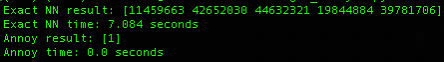

In [ ]:

from IPython.display import Image, display

display(Image(filename='/content/bukti_local.png'))


***Pertanyaannya: Kenapa code dibagian build index tidak dihitung waktunya?***

Waktu build index tidak dihitung karena pengujian ini hanya membandingkan waktu pencarian tetangga terdekat antara Exact NN dan Annoy. Indeks Annoy dibuat terlebih dahulu agar proses pencarian lebih cepat. Jika ingin menghitung total waktu proses, waktu pembuatan indeks juga harus ikut dihitung

## **Praktikum 2 FAISS**

In [ ]:
!pip install faiss-cpu

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Waktu Exact: 0.00014972686767578125
Waktu IVF+PQ: 0.0003345012664794922


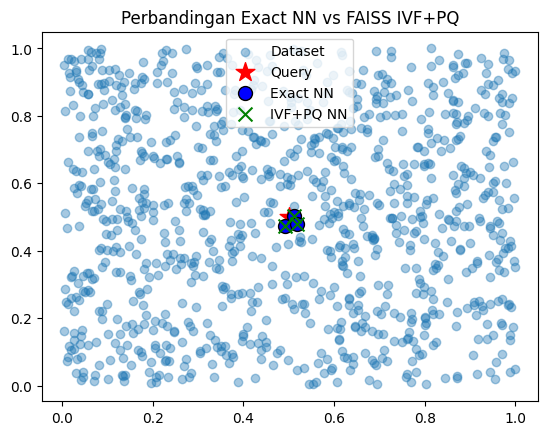

In [ ]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

# 1. Buat dataset 2D sederhana
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 titik 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query di tengah

# 2. Exact NN dengan IndexFlatL2 (brute force tapi cepat)
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # cari 3 tetangga terdekat
end = time.time()
time_flat = end - start

# 3. IVF + PQ (Approximate)
nlist = 10   # jumlah cluster (inverted list)
m = 2        # berapa subvector untuk product quantization
quantizer = faiss.IndexFlatL2(2)   # dipakai IVF untuk cluster awal
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bit per subvector

index_ivfpq.train(X)  # training centroid
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

# 4. Print hasil
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Waktu Exact:", time_flat)
print("Waktu IVF+PQ:", time_ivfpq)

# 5. Visualisasi
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

# Tetangga dari Flat
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

# Tetangga dari IVF+PQ
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ")
plt.show()


**Melakukan percobaan pada metric distance yang berbeda**

In [ ]:

import faiss
import numpy as np
import time

# Mengatur jumlah thread
faiss.omp_set_num_threads(4)

# Percobaan
jumlah_data_list = [1000, 1000000]
dimensi_list = [2, 5]
metrik_list = ["Euclidean", "Cosine"]

k = 3
nlist = 10
nbits = 8

for metrik in metrik_list:
    for dimensi in dimensi_list:
        for jumlah_data in jumlah_data_list:

            print("\n" + "=" * 50)
            print("Metrik          :", metrik)
            print("Dimensi data    :", dimensi, "D")
            print("Jumlah data     :", jumlah_data)

            # Membuat data acak
            np.random.seed(42)
            data = np.random.random(
                (jumlah_data, dimensi)
            ).astype("float32")

            query = np.random.random(
                (1, dimensi)
            ).astype("float32")

            # Menyesuaikan data untuk Cosine Similarity
            if metrik == "Cosine":
                faiss.normalize_L2(data)
                faiss.normalize_L2(query)

                index_flat = faiss.IndexFlatIP(dimensi)

                quantizer = faiss.IndexFlatIP(dimensi)
                index_ivfpq = faiss.IndexIVFPQ(
                    quantizer,
                    dimensi,
                    nlist,
                    dimensi,
                    nbits,
                    faiss.METRIC_INNER_PRODUCT
                )

            else:
                index_flat = faiss.IndexFlatL2(dimensi)

                quantizer = faiss.IndexFlatL2(dimensi)
                index_ivfpq = faiss.IndexIVFPQ(
                    quantizer,
                    dimensi,
                    nlist,
                    dimensi,
                    nbits,
                    faiss.METRIC_L2
                )

            # Exact Nearest Neighbor (ENN)
            index_flat.add(data)

            start = time.perf_counter()
            jarak_enn, indeks_enn = index_flat.search(query, k)
            waktu_enn = time.perf_counter() - start

            # Approximate Nearest Neighbor (ANN)
            start_build = time.perf_counter()

            index_ivfpq.train(data)
            index_ivfpq.add(data)

            waktu_build = time.perf_counter() - start_build

            start = time.perf_counter()
            jarak_ann, indeks_ann = index_ivfpq.search(query, k)
            waktu_ann = time.perf_counter() - start

            print("\nHasil Exact Nearest Neighbor (ENN)")
            print("Indeks terdekat :", indeks_enn[0])
            print("Jarak           :", jarak_enn[0])
            print("Waktu pencarian :", round(waktu_enn * 1000, 4), "ms")

            print("\nHasil Approximate Nearest Neighbor (ANN)")
            print("Indeks terdekat :", indeks_ann[0])
            print("Jarak           :", jarak_ann[0])
            print("Waktu pencarian :", round(waktu_ann * 1000, 4), "ms")
            print("Waktu train + build index :",
                  round(waktu_build, 4), "detik")



Metrik          : Euclidean
Dimensi data    : 2 D
Jumlah data     : 1000

Hasil Exact Nearest Neighbor (ENN)
Indeks terdekat : [112 535 777]
Jarak           : [2.1161813e-05 1.3761134e-03 2.3510854e-03]
Waktu pencarian : 0.0868 ms

Hasil Approximate Nearest Neighbor (ANN)
Indeks terdekat : [112 777 548]
Jarak           : [1.6702339e-05 2.3584329e-03 5.3988304e-03]
Waktu pencarian : 0.0962 ms
Waktu train + build index : 0.0392 detik

Metrik          : Euclidean
Dimensi data    : 2 D
Jumlah data     : 1000000

Hasil Exact Nearest Neighbor (ENN)
Indeks terdekat : [132774 119034 511191]
Jarak           : [1.3411045e-07 3.2782555e-07 4.0233135e-07]
Waktu pencarian : 7.118 ms

Hasil Approximate Nearest Neighbor (ANN)
Indeks terdekat : [132774 410129 511191]
Jarak           : [2.1234155e-07 2.1234155e-07 2.1234155e-07]
Waktu pencarian : 0.9379 ms
Waktu train + build index : 9.6944 detik

Metrik          : Euclidean
Dimensi data    : 5 D
Jumlah data     : 1000

Hasil Exact Nearest Neighbor (E

**Tabel Hasil Praktikum FAISS**

| Metrik Distance | Dimensi | Jumlah Data | Indeks ENN | Indeks ANN | Waktu ENN (ms) | Waktu ANN (ms) | Train + Build (detik) |
|---|---|---:|---|---|---:|---:|---:|
| Euclidean | 2D | 1.000 | 112, 535, 777 | 112, 777, 548 | 0.0868 | 0.0962 | 0.0392 |
| Euclidean | 2D | 1.000.000 | 132774, 119034, 511191 | 132774, 410129, 511191 | 7.1180 | 0.9379 | 9.6944 |
| Euclidean | 5D | 1.000 | 988, 780, 27 | 988, 780, 27 | 0.0282 | 0.0961 | 0.0834 |
| Euclidean | 5D | 1.000.000 | 901095, 495168, 561017 | 901095, 561017, 495168 | 13.7577 | 1.1717 | 22.7351 |
| Cosine | 2D | 1.000 | 738, 183, 561 | 91, 26, 965 | 0.3881 | 0.1325 | 0.0557 |
| Cosine | 2D | 1.000.000 | 18017, 8795, 2356 | 37751, 34876, 30476 | 3.9589 | 0.9240 | 8.3486 |
| Cosine | 5D | 1.000 | 988, 943, 780 | 988, 943, 780 | 0.0293 | 0.1000 | 0.0800 |
| Cosine | 5D | 1.000.000 | 653774, 135588, 561017 | 314338, 163986, 817864 | 3.8092 | 1.1617 | 23.0151 |

Keterangan:
- **ENN:** Exact Nearest Neighbor.
- **ANN:** Approximate Nearest Neighbor.
- Waktu ENN dan ANN menunjukkan waktu pencarian saja.
- Train + Build menunjukkan waktu untuk pelatihan dan pembuatan indeks ANN.

## **Praktikum 3 HNSW**

In [ ]:
!pip install hnswlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679800 sha256=df9d345949156ed640240d8369f3e5cf4f9d6c115e6d37d003bd7d5277045b17
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50e3ef0b67e
Successfully built hnswlib


In [ ]:
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

# ===========================
# 1. Buat data 2D acak
# ===========================
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # cari 5 tetangga terdekat

# ===========================
# 2. Exact NN (Brute Force)
# ===========================
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Waktu:", end - start, "detik")

# ===========================
# 3. HNSW
# ===========================
# Inisialisasi index HNSW
p = hnswlib.Index(space='l2', dim=dim)

# Ukuran maksimum elemen yang bisa ditampung
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Tambahkan data
p.add_items(data)

# Set parameter pencarian
p.set_ef(50)   # tradeoff speed vs accuracy

start = time.time()
labels, distances = p.knn_query(query, k=k)
end = time.time()

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances:", distances)
print("Waktu:", end - start, "detik")


=== Exact NN ===
Indices: [[993 964 788 528  16]]
Distances: [[0.01145547 0.02310762 0.0234505  0.02675764 0.0279675 ]]
Waktu: 0.044138193130493164 detik

=== HNSW ===
Indices: [[993 964 788 528  16]]
Distances: [[0.00013123 0.00053396 0.00054993 0.00071597 0.00078218]]
Waktu: 0.00017261505126953125 detik


**Melakukan percobaan pada metric distance yang berbeda**

In [ ]:

import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

# Pengaturan percobaan
jumlah_data_list = [1000, 1000000]
dimensi_list = [2, 5]
metrik_list = ["Euclidean", "Cosine"]
k = 5

for metrik in metrik_list:
    for dim in dimensi_list:
        for jumlah_data in jumlah_data_list:

            print("\n" + "=" * 55)
            print("Metrik       :", metrik)
            print("Dimensi      :", str(dim) + "D")
            print("Jumlah data  :", jumlah_data)

            # Membuat data acak
            np.random.seed(42)
            data = np.random.random(
                (jumlah_data, dim)
            ).astype(np.float32)

            query = np.full((1, dim), 0.5, dtype=np.float32)

            # Menentukan metrik
            if metrik == "Euclidean":
                metric_sklearn = "euclidean"
                metric_hnsw = "l2"
            else:
                metric_sklearn = "cosine"
                metric_hnsw = "cosine"

            # =================================
            # 1. Exact Nearest Neighbor (ENN)
            # =================================
            nn = NearestNeighbors(
                n_neighbors=k,
                algorithm="brute",
                metric=metric_sklearn,
                n_jobs=-1
            )

            nn.fit(data)

            start = time.perf_counter()
            distances_enn, indices_enn = nn.kneighbors(query)
            waktu_enn = time.perf_counter() - start

            print("\n=== Exact NN (ENN) ===")
            print("Indeks terdekat :", indices_enn[0])
            print("Jarak           :", distances_enn[0])
            print("Waktu pencarian :", round(waktu_enn * 1000, 4), "ms")

            # =================================
            # 2. HNSW
            # =================================
            index = hnswlib.Index(
                space=metric_hnsw,
                dim=dim
            )

            start_build = time.perf_counter()

            index.init_index(
                max_elements=jumlah_data,
                ef_construction=100,
                M=16
            )

            index.add_items(data)
            waktu_build = time.perf_counter() - start_build

            index.set_ef(50)

            start = time.perf_counter()
            labels, distances_hnsw = index.knn_query(query, k=k)
            waktu_hnsw = time.perf_counter() - start

            # HNSW dengan space='l2' menghasilkan jarak kuadrat.
            # Akar kuadrat digunakan agar sebanding dengan Euclidean.
            if metrik == "Euclidean":
                distances_hnsw = np.sqrt(
                    np.maximum(distances_hnsw, 0)
                )

            print("\n=== HNSW ===")
            print("Indeks terdekat :", labels[0])
            print("Jarak           :", distances_hnsw[0])
            print("Waktu pencarian :", round(waktu_hnsw * 1000, 4), "ms")
            print("Waktu build index:", round(waktu_build, 4), "detik")



Metrik       : Euclidean
Dimensi      : 2D
Jumlah data  : 1000

=== Exact NN (ENN) ===
Indeks terdekat : [137 170 750 316 991]
Jarak           : [0.01144331 0.0278216  0.02824018 0.03417073 0.04514859]
Waktu pencarian : 1.3778 ms

=== HNSW ===
Indeks terdekat : [137 170 750 316 991]
Jarak           : [0.01144331 0.0278216  0.02824018 0.03417073 0.04514859]
Waktu pencarian : 0.1497 ms
Waktu build index: 0.0477 detik

Metrik       : Euclidean
Dimensi      : 2D
Jumlah data  : 1000000

=== Exact NN (ENN) ===
Indeks terdekat : [286942 583487 695123 948064 829288]
Jarak           : [0.00059132 0.00100753 0.0011289  0.00156647 0.00178818]
Waktu pencarian : 47.9989 ms

=== HNSW ===
Indeks terdekat : [286942 583487 695123 948064 829288]
Jarak           : [0.00059132 0.00100753 0.0011289  0.00156647 0.00178818]
Waktu pencarian : 0.1844 ms
Waktu build index: 53.197 detik

Metrik       : Euclidean
Dimensi      : 5D
Jumlah data  : 1000

=== Exact NN (ENN) ===
Indeks terdekat : [895 451 375 386 411

**Tabel Hasil Percobaan HNSW**

| Metrik Distance | Dimensi | Jumlah Data | Indeks ENN | Indeks HNSW | Waktu ENN (ms) | Waktu HNSW (ms) | Build Index (detik) |
|---|---|---:|---|---|---:|---:|---:|
| Euclidean | 2D | 1.000 | 137, 170, 750, 316, 991 | 137, 170, 750, 316, 991 | 1.3778 | 0.1497 | 0.0477 |
| Euclidean | 2D | 1.000.000 | 286942, 583487, 695123, 948064, 829288 | 286942, 583487, 695123, 948064, 829288 | 47.9989 | 0.1844 | 53.1970 |
| Euclidean | 5D | 1.000 | 895, 451, 375, 386, 411 | 895, 451, 375, 386, 411 | 1.0119 | 0.0869 | 0.0463 |
| Euclidean | 5D | 1.000.000 | 794791, 501340, 912100, 84056, 660781 | 794791, 501340, 912100, 84056, 660781 | 33.8794 | 0.2552 | 87.5523 |
| Cosine | 2D | 1.000 | 2, 135, 413, 210, 700 | 2, 135, 413, 210, 700 | 26.7230 | 0.1428 | 0.0549 |
| Cosine | 2D | 1.000.000 | 469917, 383546, 49557, 317128, 87009 | 218641, 536702, 643863, 770704, 984390 | 71.6693 | 0.2128 | 87.6687 |
| Cosine | 5D | 1.000 | 248, 386, 229, 230, 437 | 248, 386, 229, 230, 437 | 14.2452 | 0.0742 | 0.0475 |
| Cosine | 5D | 1.000.000 | 422252, 464287, 605535, 319582, 869360 | 422252, 464287, 605535, 319582, 869360 | 53.8079 | 0.1956 | 83.4448 |

Keterangan:
- **ENN**: Exact Nearest Neighbor, mencari tetangga terdekat secara tepat.
- **HNSW**: metode pencarian tetangga terdekat menggunakan indeks graf.
- Waktu pencarian tidak termasuk waktu pembuatan indeks.
- Build Index adalah waktu untuk membangun indeks HNSW sebelum pencarian.

## **Praktikum 4**

In [ ]:
import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

# ===============================
# 1. Buat dataset 1 juta data 5D
# ===============================
n_data = 1_000_000   # bisa coba 100_000 dulu jika RAM terbatas
dim = 5
X = np.random.random((n_data, dim)).astype(np.float32)

# Query point
query = np.random.random((1, dim)).astype(np.float32)
k = 10

# ===============================
# 2. Annoy
# ===============================
print("=== Annoy ===")
ann_index = AnnoyIndex(dim, 'euclidean')

start = time.time()
for i in range(n_data):
    ann_index.add_item(i, X[i])
ann_index.build(10)  # 10 trees
build_time = time.time() - start

start = time.time()
neighbors = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", neighbors[0][:5], "...")

# ===============================
# 3. FAISS (Flat Index)
# ===============================
print("\n=== FAISS (IndexFlatL2) ===")
faiss_index = faiss.IndexFlatL2(dim)

start = time.time()
faiss_index.add(X)
build_time = time.time() - start

start = time.time()
distances, indices = faiss_index.search(query, k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", indices[0][:5], "...")

# ===============================
# 4. HNSW (hnswlib)
# ===============================
print("\n=== HNSW (hnswlib) ===")
hnsw_index = hnswlib.Index(space='l2', dim=dim)

start = time.time()
hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw_index.add_items(X)
build_time = time.time() - start

hnsw_index.set_ef(50)

start = time.time()
labels, distances = hnsw_index.knn_query(query, k=k)
query_time = time.time() - start

print("Build time:", build_time, "detik")
print("Query time:", query_time, "detik")
print("Neighbors:", labels[0][:5], "...")


=== Annoy ===
Build time: 20.94272494316101 detik
Query time: 0.0003571510314941406 detik
Neighbors: [13613, 48169, 416789, 146613, 530906] ...

=== FAISS (IndexFlatL2) ===
Build time: 0.009773731231689453 detik
Query time: 0.015027284622192383 detik
Neighbors: [ 13613  48169 623361 416789 146613] ...

=== HNSW (hnswlib) ===
Build time: 166.58883118629456 detik
Query time: 0.00040149688720703125 detik
Neighbors: [ 13613  48169 623361 416789 146613] ...


**Melakukan percobaan pada metric distance yang berbeda**

In [ ]:

import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

# =================================
# 1. Membuat dataset
# =================================
np.random.seed(42)

n_data = 1_000_000
dim = 5
k = 10

X = np.random.random((n_data, dim)).astype(np.float32)
query = np.random.random((1, dim)).astype(np.float32)

# Menyiapkan data ternormalisasi untuk Cosine
X_cosine = X.copy()
query_cosine = query.copy()

faiss.normalize_L2(X_cosine)
faiss.normalize_L2(query_cosine)

for metric in ["Euclidean", "Cosine"]:

    print("\n" + "=" * 60)
    print("METRIK DISTANCE:", metric)
    print("Jumlah data:", n_data)
    print("Dimensi:", dim)

    if metric == "Euclidean":
        data = X
        query_data = query
        annoy_metric = "euclidean"
        hnsw_metric = "l2"
    else:
        data = X_cosine
        query_data = query_cosine
        annoy_metric = "angular"
        hnsw_metric = "cosine"

    # =================================
    # 2. Annoy
    # =================================
    print("\n=== Annoy ===")

    annoy_index = AnnoyIndex(dim, annoy_metric)

    start = time.perf_counter()

    for i in range(n_data):
        annoy_index.add_item(i, data[i])

    annoy_index.build(10)

    annoy_build = time.perf_counter() - start

    start = time.perf_counter()

    annoy_neighbors, annoy_distances = (
        annoy_index.get_nns_by_vector(
            query_data[0],
            k,
            include_distances=True
        )
    )

    annoy_query = time.perf_counter() - start

    print("Build time:", round(annoy_build, 4), "detik")
    print("Query time:", round(annoy_query, 6), "detik")
    print("5 indeks terdekat:", annoy_neighbors[:5])
    print("Jarak/skor:", annoy_distances[:5])

    # =================================
    # 3. FAISS
    # =================================
    print("\n=== FAISS ===")

    if metric == "Euclidean":
        faiss_index = faiss.IndexFlatL2(dim)
    else:
        faiss_index = faiss.IndexFlatIP(dim)

    start = time.perf_counter()
    faiss_index.add(data)
    faiss_build = time.perf_counter() - start

    start = time.perf_counter()
    faiss_distances, faiss_indices = faiss_index.search(
        query_data, k
    )
    faiss_query = time.perf_counter() - start

    print("Build time:", round(faiss_build, 4), "detik")
    print("Query time:", round(faiss_query, 6), "detik")
    print("5 indeks terdekat:", faiss_indices[0][:5])

    if metric == "Euclidean":
        print("Jarak kuadrat:", faiss_distances[0][:5])
    else:
        print("Skor cosine:", faiss_distances[0][:5])

    # =================================
    # 4. HNSW
    # =================================
    print("\n=== HNSW ===")

    hnsw_index = hnswlib.Index(
        space=hnsw_metric,
        dim=dim
    )

    start = time.perf_counter()

    hnsw_index.init_index(
        max_elements=n_data,
        ef_construction=200,
        M=16
    )

    hnsw_index.add_items(data)
    hnsw_build = time.perf_counter() - start

    hnsw_index.set_ef(50)

    start = time.perf_counter()
    hnsw_labels, hnsw_distances = hnsw_index.knn_query(
        query_data, k=k
    )
    hnsw_query = time.perf_counter() - start

    print("Build time:", round(hnsw_build, 4), "detik")
    print("Query time:", round(hnsw_query, 6), "detik")
    print("5 indeks terdekat:", hnsw_labels[0][:5])
    print("Jarak:", hnsw_distances[0][:5])



METRIK DISTANCE: Euclidean
Jumlah data: 1000000
Dimensi: 5

=== Annoy ===
Build time: 19.7372 detik
Query time: 0.00012 detik
5 indeks terdekat: [901095, 495168, 561017, 163986, 185734]
Jarak/skor: [0.03896911442279816, 0.04706490412354469, 0.047291096299886703, 0.05475503206253052, 0.06032349541783333]

=== FAISS ===
Build time: 0.0084 detik
Query time: 0.00989 detik
5 indeks terdekat: [901095 495168 561017 163986 185734]
Jarak kuadrat: [0.00151873 0.00221491 0.00223637 0.00299835 0.00363874]

=== HNSW ===
Build time: 166.9184 detik
Query time: 0.000167 detik
5 indeks terdekat: [901095 495168 561017 163986 185734]
Jarak: [0.00151859 0.00221511 0.00223645 0.00299811 0.00363892]

METRIK DISTANCE: Cosine
Jumlah data: 1000000
Dimensi: 5

=== Annoy ===
Build time: 27.3544 detik
Query time: 0.000139 detik
5 indeks terdekat: [653774, 135588, 561017, 901095, 211473]
Jarak/skor: [0.020667048171162605, 0.02392578311264515, 0.024496929720044136, 0.026538435369729996, 0.028229668736457825]

=== 

**Tabel Hasil Praktikum 4: Perbandingan Annoy, FAISS, dan HNSW**

| Metrik Distance | Metode | Jumlah Data | Dimensi | 5 Indeks Terdekat | Build Time (detik) | Query Time (detik) |
|---|---|---:|---:|---|---:|---:|
| Euclidean | Annoy | 1.000.000 | 5D | 901095, 495168, 561017, 163986, 185734 | 19.7372 | 0.000120 |
| Euclidean | FAISS | 1.000.000 | 5D | 901095, 495168, 561017, 163986, 185734 | 0.0084 | 0.009890 |
| Euclidean | HNSW | 1.000.000 | 5D | 901095, 495168, 561017, 163986, 185734 | 166.9184 | 0.000167 |
| Cosine | Annoy | 1.000.000 | 5D | 653774, 135588, 561017, 901095, 211473 | 27.3544 | 0.000139 |
| Cosine | FAISS | 1.000.000 | 5D | 653774, 135588, 561017, 901095, 211473 | 0.0083 | 0.004052 |
| Cosine | HNSW | 1.000.000 | 5D | 653774, 135588, 561017, 901095, 211473 | 156.6550 | 0.000210 |

**Keterangan:**
- **Build Time** adalah waktu yang dibutuhkan untuk membangun atau mengisi indeks.
- **Query Time** adalah waktu yang dibutuhkan untuk mencari tetangga terdekat.
- Semua percobaan menggunakan 1.000.000 data dengan dimensi 5D dan \(k=10\), tetapi tabel menampilkan lima indeks terdekat pertama sesuai output.

## **Praktikum 5**

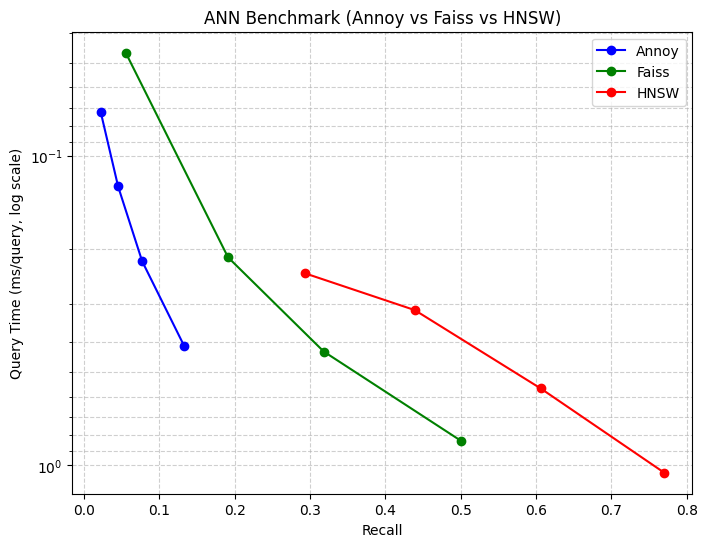

In [ ]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Dataset random
# -------------------------------
d = 128        # dimensi
nb = 100000    # jumlah database vector
nq = 1000      # jumlah query

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth dengan FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Fungsi recall
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Benchmark Annoy
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark FAISS IVF
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Benchmark HNSW
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Jalankan benchmark dengan beberapa parameter
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# -------------------------------
# Visualisasi trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, makin kanan makin turun
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

## **Praktikum 6**

In [ ]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Load dataset
# -------------------------------
df = pd.read_csv(
    '/content/songs_with_attributes_and_lyrics.csv',
    encoding='latin1',
    engine='python',
    on_bad_lines='warn'
)

features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
X = df[features].values

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact Nearest Neighbor (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=X_scaled.shape[1])
p_hnsw.init_index(max_elements=X_scaled.shape[0], ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, dist_hnsw = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()

d = X_scaled.shape[1]
nlist = 100

quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(
    quantizer, d, nlist, faiss.METRIC_L2
)

index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10

dist_faiss, idx_faiss = index_faiss.search(X_scaled, k)

time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Contoh tampilkan top-5 neighbors dari item pertama
# -------------------------------
print("\nTop-5 neighbors for first song:")
print(f"Exact NN: {idx_exact[0][:5]}")
print(f"Annoy:    {idx_annoy[0][:5]}")
print(f"HNSW:     {idx_hnsw[0][:5]}")
print(f"FAISS:    {idx_faiss[0][:5]}")

/tmp/ipykernel_7925/309726620.py:13: ParserWarning: Skipping line 53551: unexpected end of data

  df = pd.read_csv(


Exact NN done in 17.829 s
Annoy done in 3.582 s
HNSW done in 10.991 s
FAISS IVF done in 4.489 s

Top-5 neighbors for first song:
Exact NN: [    0  3836 35205 41311 18028]
Annoy:    [0, 3836, 35205, 41311, 18028]
HNSW:     [    0  3836 35205 41311 18028]
FAISS:    [    0  3836 35205 41311 18028]


**Analisis**

Di praktikum ini dilakukan perbandingan Exact NN, Annoy, HNSWLIB, dan FAISS IVF menggunakan sembilan fitur numerik dari dataset Micro Spotify yang dinormalisasi dengan `StandardScaler`.

Hasil pengujian melihatkan waktu eksekusi Exact NN sebesar 17,829 detik, Annoy 3,582 detik, HNSWLIB 10,991 detik, dan FAISS IVF 4,489 detik. Annoy menjadi metode dengan waktu eksekusi paling singkat.

Keempat metode menghasilkan lima indeks tetangga terdekat yang sama, `[0, 3836, 35205, 41311, 18028]`. Ini melihatkan bahwa hasil pencarian pada lagu pertama sama dengan Exact NN. tapi, hasil tersebut belum membuktikan bahwa semua pencarian memiliki akurasi yang sama.

Selama percobaan, terdapat kendala saat membaca CSV, yaitu masalah format teks dan encoding. Beberapa baris dilewati saat pembacaan data. Selain itu, FAISS sempat mengalami `TypeError` karena penggunaan argumen `nlist`, tetapi berhasil diatasi dengan menuliskan argumen secara berurutan.

## **Tugas**

In [ ]:
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors
from annoy import AnnoyIndex
import hnswlib
import faiss
from sklearn.preprocessing import StandardScaler

# -------------------------------
# Contoh dataset kecil untuk testing
# -------------------------------
np.random.seed(42)
n_samples = 10000   # jumlah database vector
d = 128             # dimensi
X = np.random.random((n_samples, d)).astype('float32')

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

# -------------------------------
# Exact NN (brute-force)
# -------------------------------
start = time.time()
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)
dist_exact, idx_exact = nn.kneighbors(X_scaled)
time_exact = time.time() - start
print(f"Exact NN done in {time_exact:.3f} s")

# -------------------------------
# Annoy
# -------------------------------
start = time.time()
f = X_scaled.shape[1]
index_annoy = AnnoyIndex(f, 'euclidean')
for i, v in enumerate(X_scaled):
    index_annoy.add_item(i, v)
index_annoy.build(10)
idx_annoy = [index_annoy.get_nns_by_vector(v, k) for v in X_scaled]
time_annoy = time.time() - start
print(f"Annoy done in {time_annoy:.3f} s")

# -------------------------------
# HNSW
# -------------------------------
start = time.time()
p_hnsw = hnswlib.Index(space='l2', dim=d)
p_hnsw.init_index(max_elements=n_samples, ef_construction=200, M=16)
p_hnsw.add_items(X_scaled)
p_hnsw.set_ef(200)
idx_hnsw, _ = p_hnsw.knn_query(X_scaled, k=k)
time_hnsw = time.time() - start
print(f"HNSW done in {time_hnsw:.3f} s")

# -------------------------------
# FAISS IVF
# -------------------------------
start = time.time()

quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(
    quantizer, d, 100, faiss.METRIC_L2
)

index_faiss.train(X_scaled)
index_faiss.add(X_scaled)
index_faiss.nprobe = 10

_, idx_faiss = index_faiss.search(X_scaled, k)

time_faiss = time.time() - start
print(f"FAISS IVF done in {time_faiss:.3f} s")

# -------------------------------
# Tampilkan ringkasan waktu
# -------------------------------
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}")
print(f"Annoy    : {time_annoy:.3f}")
print(f"HNSW     : {time_hnsw:.3f}")
print(f"FAISS    : {time_faiss:.3f}")


Exact NN done in 2.821 s
Annoy done in 0.606 s
HNSW done in 5.321 s
FAISS IVF done in 0.454 s

=== Ringkasan Waktu (detik) ===
Exact NN : 2.821
Annoy    : 0.606
HNSW     : 5.321
FAISS    : 0.454


### **Hasil android**

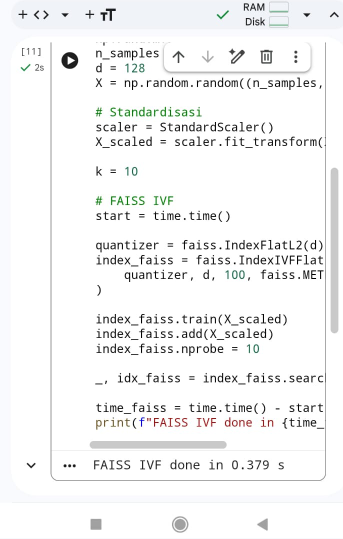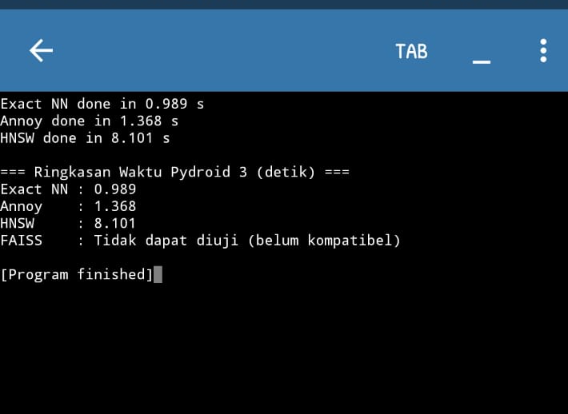

### **Analisis Perbandingan ANN di Google Colab dan Pydroid 3**

**Tabel**

| Metode | Laptop (Google Colab) | Android (Pydroid 3) |
|---|---:|---:|
| Exact NN | 2,821 detik | 0,989 detik |
| Annoy | 0,606 detik | 1,368 detik |
| HNSW | 5,321 detik | 8,101 detik |
| FAISS IVF | 0,454 detik | Tidak berhasil dijalankan |

**Analisis Hasil**

Berdasarkan hasil pengujian, waktu eksekusi setiap metode berbeda antara Google Colab dan Pydroid 3. Pada laptop melalui Google Colab, FAISS IVF menjadi metode tercepat dengan waktu 0,454 detik, diikuti Annoy sebesar 0,606 detik. Sementara itu, pada Android, Exact NN menjadi yang tercepat dengan waktu 0,989 detik, sedangkan HNSW membutuhkan waktu paling lama, yaitu 8,101 detik.

Annoy dan HNSW membutuhkan waktu lebih lama pada Android dibandingkan Google Colab. Sebaliknya, Exact NN justru lebih cepat pada pengujian Android ini. Hal tersebut menunjukkan bahwa hasil waktu eksekusi dapat berbeda bergantung pada lingkungan pengujian dan kondisi perangkat saat program dijalankan.

FAISS IVF tidak dapat dibandingkan secara langsung karena tidak berhasil dijalankan di Pydroid 3 akibat kendala instalasi library. Oleh karena itu, perbandingan untuk metode tersebut hanya tersedia pada Google Colab.

**Kendala Pengujian**

Kendala ditemukan saat memasang FAISS pada Pydroid 3. Proses instalasi `faiss-cpu` gagal karena perintah `swig` tidak ditemukan ketika paket dibangun. Oleh karena itu, FAISS IVF hanya berhasil diuji di Google Colab. Hasil FAISS untuk smartphone tidak dicantumkan sebagai waktu eksekusi karena metode tersebut belum berhasil dijalankan pada perangkat tersebut.

**Spesifikasi android**

- Merek dan model: Xiaomi Redmi Note 9 Pro
- Sistem operasi: Android 11
- RAM: 8 GB
- CPU: Octa-core, kecepatan maksimum 2,32 GHz
- Aplikasi pengujian: Pydroid 3
- Dataset: 10.000 vektor
- Dimensi vektor: 128
- Jumlah nearest neighbors (k): 10